# Tugas 7: Visualisasi Data dengan Matplotlib

Ini versi sederhana dari notebook Tugas 7, ditulis supaya mudah dibaca pemula. Jalankan sel dari atas ke bawah. Notebook ini lanjutan Tugas 6 dan memakai data yang sama: `paket_a_transaksi_pos_2024_2025.csv` (transaksi Point of Sale 2024–2025). Semua grafik hanya untuk **tahun 2025** dan ditampilkan dalam **satu grid 2×2**.

| Posisi | Bagian | Visualisasi |
|---|---|---|
| Kiri atas | 1 | Penjualan per bulan tahun 2025 |
| Kanan atas | 2 | 10 produk terlaris tahun 2025 |
| Kiri bawah | 3 | Proporsi transaksi berhasil vs gagal/batal tahun 2025 |
| Kanan bawah | 4 | Hubungan jumlah beli dengan diskon |

**Aturan yang dipakai** (dicatat supaya angkanya bisa dipertanggungjawabkan):
- Pembersihan data mengikuti Tugas 6: harga dirapikan, `jumlah` negatif diubah jadi positif, `kode_kasir` kosong diisi `K_UNKNOWN`.
- Beda dari Tugas 6: **duplikat dibuang** dan **`jumlah` di atas 12 dibuang**. Angka sebesar 2.375 unit jelas salah input dan bisa merusak tampilan grafik. Batas 12 mengikuti Tugas 5.
- Penjualan dihitung dari `Total_Bersih` (sudah dipotong diskon dan ditambah PPN 11%, sama seperti Tugas 6), hanya untuk transaksi `SELESAI`.
- "Terlaris" diukur dari total **unit** yang terjual (transaksi `SELESAI`).
- Bagian 3 memakai semua status. `SELESAI`, `BATAL`, dan `RETUR` ditampilkan terpisah.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Pengaturan dasar
TAHUN = 2025
SEED = 42                                   # supaya geseran acak di Bagian 4 selalu sama
np.random.seed(SEED)
FILE_DATA = Path("../Tugas_5/data/paket_a_transaksi_pos_2024_2025.csv")
Path("hasil").mkdir(exist_ok=True)          # folder untuk menyimpan gambar

# Nama bulan dan warna yang dipakai di semua grafik
BULAN = ["Jan", "Feb", "Mar", "Apr", "Mei", "Jun", "Jul", "Agu", "Sep", "Okt", "Nov", "Des"]
BIRU, ORANYE, ABU = "#2F6DB5", "#D9822B", "#8A8F98"

# Gaya grafik: garis bantu tipis, tanpa garis tepi atas dan kanan
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

**Penjelasan.** Sel ini menyiapkan alat dan pengaturan dasar: library (`pandas` untuk tabel, `numpy` untuk hitungan, `matplotlib` untuk grafik), tahun yang dianalisis, lokasi file data, daftar nama bulan, dan tiga warna. `SEED` membuat geseran acak di Bagian 4 selalu sama setiap kali notebook dijalankan.

In [2]:
df = pd.read_csv(FILE_DATA)
print("Jumlah baris awal   :", len(df))

# Hapus baris yang sama persis (duplikat)
df = df.drop_duplicates()
print("Setelah hapus duplikat:", len(df))
df.head()

Jumlah baris awal   : 5030
Setelah hapus duplikat: 5000


,id_transaksi,tanggal,kode_gerai,kode_kasir,kode_produk,jumlah,harga_satuan,diskon_persen,status
0,TRX0241065,2025-06-02,G09,K011,RMT1402,4,13000,0,SELESAI
1,TRX0240510,2024-12-28,G09,K015,SGR1205,1,21000,0,SELESAI
2,TRX0244483,2024-09-04,G11,K029,RMT1407,3,"7500,00",0,SELESAI
3,TRX0242532,2025-07-30,G05,K001,MKN1103,2,6500,0,SELESAI
4,TRX0243509,26/03/2025,G05,K016,RMT1407,1,6000,0,SELESAI


**Penjelasan.** Sel ini membaca file CSV ke dalam tabel `df` (DataFrame), lalu menghapus baris yang sama persis (duplikat). `len(df)` menghitung jumlah baris, jadi kita bisa melihat berapa baris yang hilang.

In [3]:
# 1. Harga: ada yang ditulis "13.000" (titik ribuan) dan "7500,00" (koma desimal)
def bersihkan_harga(teks):
    teks = teks.split(",")[0]       # "7500,00" -> "7500"
    teks = teks.replace(".", "")    # "13.000"  -> "13000"
    return int(teks)

df["harga_satuan"] = df["harga_satuan"].apply(bersihkan_harga)

# 2. Tanggal: ada tiga format, semuanya diubah jadi tanggal asli
df["tanggal"] = pd.to_datetime(df["tanggal"], format="mixed", dayfirst=True)

# 3. Jumlah negatif (retur/koreksi) dijadikan positif, seperti Tugas 6
print("Jumlah negatif:", (df["jumlah"] < 0).sum())
df["jumlah"] = df["jumlah"].abs()

# 4. Kode kasir yang kosong diisi K_UNKNOWN, seperti Tugas 6
df["kode_kasir"] = df["kode_kasir"].fillna("K_UNKNOWN")

# 5. Jumlah di atas 12 dianggap salah input, jadi dibuang
print("Jumlah di atas 12 (dibuang):", (df["jumlah"] > 12).sum())
df = df[df["jumlah"] <= 12]

# 6. Hitung Total_Bersih: (harga x jumlah) dikurangi diskon, lalu ditambah PPN 11%
df["Total_Bersih"] = df["harga_satuan"] * df["jumlah"] * (1 - df["diskon_persen"] / 100) * 1.11

print("Baris yang tersisa:", len(df))

Jumlah negatif: 40
Jumlah di atas 12 (dibuang): 12
Baris yang tersisa: 4988


**Penjelasan.** Data mentah masih berantakan, jadi dirapikan satu per satu:
1. **Harga**: ada yang ditulis `13.000` (titik ribuan) dan `7500,00` (koma desimal). Fungsi `bersihkan_harga` membuang koma dan titiknya, lalu mengubahnya jadi angka.
2. **Tanggal**: ada tiga format penulisan. `pd.to_datetime` menyeragamkannya jadi tanggal asli.
3. **Jumlah negatif** (retur atau koreksi) dijadikan positif dengan `.abs()`, sama seperti Tugas 6.
4. **Kode kasir kosong** diisi `K_UNKNOWN`, sama seperti Tugas 6.
5. **Jumlah di atas 12** dibuang karena dianggap salah input (contohnya 2.375 unit).
6. **Total_Bersih** = harga × jumlah, dikurangi diskon, lalu ditambah PPN 11%.

Jumlah baris yang terkena tiap langkah dicetak di output.

In [4]:
# d25     = semua transaksi 2025 (semua status)
# selesai = transaksi 2025 yang berhasil saja
d25 = df[df["tanggal"].dt.year == TAHUN]
selesai = d25[d25["status"] == "SELESAI"]

print("Transaksi 2025 :", len(d25))
print("Yang SELESAI   :", len(selesai))
print("Jumlah min/max :", d25["jumlah"].min(), "/", d25["jumlah"].max())
print("Nilai kosong   :", d25.isna().sum().sum())

Transaksi 2025 : 2502
Yang SELESAI   : 2365
Jumlah min/max : 1 / 12
Nilai kosong   : 0


**Penjelasan.** Data dibagi dua: `d25` berisi semua transaksi 2025 (semua status, dipakai Bagian 3), dan `selesai` berisi transaksi 2025 yang berhasil saja (dipakai Bagian 1, 2, dan 4). Hasil pengecekan: 2025 punya **2.502** transaksi, **2.365** di antaranya `SELESAI`, `jumlah` ada di rentang 1–12, dan nilai kosong tersisa = 0.

In [5]:
# Bagian 1: total penjualan tiap bulan, dalam juta Rupiah
jual_bulan = selesai.groupby(selesai["tanggal"].dt.month)["Total_Bersih"].sum()
jual_juta = jual_bulan / 1_000_000

print("Jumlah bulan  :", len(jual_juta))
print("Total setahun : Rp", f"{jual_bulan.sum():,.0f}".replace(",", "."))
print("Tertinggi     :", BULAN[jual_juta.idxmax() - 1], round(jual_juta.max(), 1), "juta")
print("Terendah      :", BULAN[jual_juta.idxmin() - 1], round(jual_juta.min(), 1), "juta")

Jumlah bulan  : 12
Total setahun : Rp 151.478.786
Tertinggi     : Mar 16.2 juta
Terendah      : Apr 10.9 juta


**Penjelasan Bagian 1.** Sel ini menjumlahkan `Total_Bersih` per bulan. `groupby` artinya "kelompokkan", jadi semua transaksi bulan yang sama dijumlahkan jadi satu angka. Hasilnya dibagi satu juta supaya angkanya mudah dibaca. Cek hasil: ada 12 bulan, dan totalnya Rp 151.478.786.

In [6]:
# Bagian 2: total unit terjual tiap produk, lalu ambil 10 terbesar
semua = selesai.groupby("kode_produk")["jumlah"].sum().sort_values(ascending=False)
top10 = semua.head(10)

print("Jumlah produk yang terjual:", len(semua))
print("Unit peringkat 10 =", semua.iloc[9], "| peringkat 11 =", semua.iloc[10])
print(top10)

Jumlah produk yang terjual: 141
Unit peringkat 10 = 118 | peringkat 11 = 111
kode_produk
RMT1408    141
MKN1100    138
SGR1205    135
MKN1108    129
PRW1309    124
MKN1109    122
SGR1204    121
RMT1406    119
SGR1207    118
RMT1404    118
Name: jumlah, dtype: int64


**Penjelasan Bagian 2.** Sel ini menjumlahkan unit yang terjual untuk tiap produk, mengurutkannya dari yang terbesar, lalu mengambil 10 teratas dengan `.head(10)`. Cek seri: peringkat 9 dan 10 sama-sama 118 unit, sedangkan peringkat 11 hanya 111 unit, jadi batas 10 besar jelas.

In [7]:
# Bagian 3: jumlah transaksi untuk tiap status
status = d25["status"].value_counts().reindex(["SELESAI", "BATAL", "RETUR"])
persen = status / status.sum() * 100

print(status)
print(persen.round(1))

status
SELESAI    2365
BATAL        88
RETUR        49
Name: count, dtype: int64
status
SELESAI    94.5
BATAL       3.5
RETUR       2.0
Name: count, dtype: float64


**Penjelasan Bagian 3.** `value_counts()` menghitung berapa kali tiap status muncul. Persennya dihitung dengan membagi tiap jumlah dengan total. `RETUR` dipisah dari `BATAL` karena kejadiannya beda: `BATAL` berarti transaksi tidak jadi, `RETUR` berarti barang sudah dibeli lalu dikembalikan. Cek hasil: jumlah ketiga status (2.502) sama dengan jumlah transaksi 2025.

In [8]:
# Bagian 4: hubungan diskon dan jumlah beli (transaksi SELESAI)
diskon = selesai["diskon_persen"]
jumlah = selesai["jumlah"]

# Titik digeser sedikit secara acak ("jitter") supaya tidak saling menumpuk.
# Geseran ini hanya untuk tampilan, perhitungan tetap memakai data asli.
diskon_geser = diskon + np.random.uniform(-1, 1, len(selesai))
jumlah_geser = jumlah + np.random.uniform(-0.25, 0.25, len(selesai))

# Ringkasan per tingkat diskon: banyak transaksi, rata-rata, median, simpangan baku
ringkas = selesai.groupby("diskon_persen")["jumlah"].agg(
    n="count", rata_rata="mean", median="median", std="std")

# Rentang wajar rata-rata (95%): semakin sedikit data, semakin lebar
ringkas["ci95"] = 1.96 * ringkas["std"] / np.sqrt(ringkas["n"])

# Kekuatan hubungan: 0 = tidak ada hubungan, mendekati 1 atau -1 = hubungan kuat
rho = diskon.corr(jumlah, method="spearman")

print(ringkas.round(2))
print("Kekuatan hubungan (rho):", round(rho, 3))

                  n  rata_rata  median   std  ci95
diskon_persen                                     
0              1801       2.59     2.0  2.31  0.11
5               165       2.64     2.0  2.45  0.37
10              201       2.63     2.0  2.53  0.35
15              131       2.44     2.0  1.84  0.32
20               67       2.40     2.0  2.22  0.53
Kekuatan hubungan (rho): -0.013


**Penjelasan Bagian 4.** Sel ini menyiapkan data untuk grafik sebar (scatter). Diskon hanya punya lima nilai (0, 5, 10, 15, 20%) dan jumlah beli selalu bilangan bulat, jadi titik-titik akan menumpuk. Karena itu tiap titik digeser sedikit secara acak (disebut *jitter*) supaya tidak saling menutupi. Geseran ini hanya untuk tampilan.

Sel ini juga menghitung tiga hal dari data asli:
- **Rata-rata dan median** jumlah beli untuk tiap tingkat diskon.
- **`ci95`**: rentang wajar untuk rata-rata tersebut. Kalau datanya sedikit, rentangnya melebar.
- **`rho`**: kekuatan hubungan diskon dan jumlah beli. Nilai 0 berarti tidak ada hubungan.

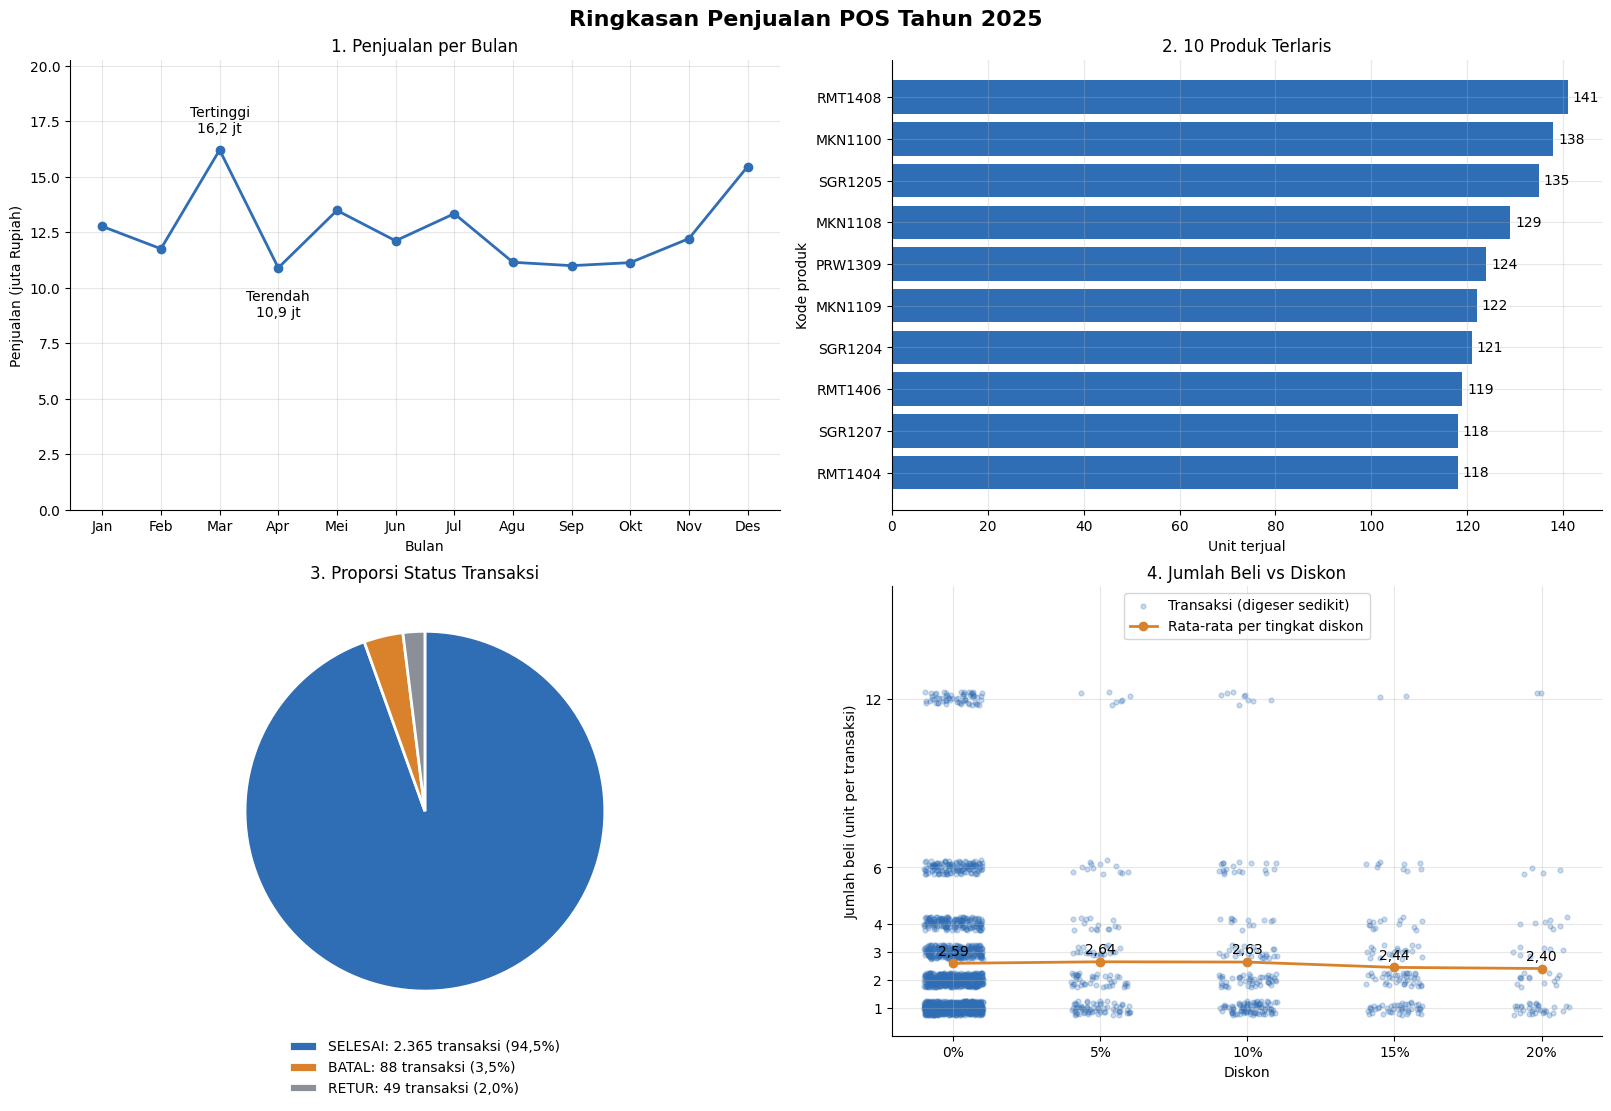

In [9]:
# Satu gambar berisi 4 grafik (2 baris x 2 kolom)
fig, axes = plt.subplots(2, 2, figsize=(16, 11), constrained_layout=True)

# ---------- Kiri atas: Bagian 1, penjualan per bulan ----------
ax = axes[0, 0]
ax.plot(BULAN, jual_juta.values, color=BIRU, marker="o", linewidth=2)

# Tulis keterangan pada bulan tertinggi dan terendah
b_max, b_min = jual_juta.idxmax(), jual_juta.idxmin()
ax.text(b_max - 1, jual_juta[b_max] + 0.8, f"Tertinggi\n{jual_juta[b_max]:.1f} jt".replace(".", ","), ha="center")
ax.text(b_min - 1, jual_juta[b_min] - 2.2, f"Terendah\n{jual_juta[b_min]:.1f} jt".replace(".", ","), ha="center")

ax.set_title("1. Penjualan per Bulan")
ax.set_xlabel("Bulan")
ax.set_ylabel("Penjualan (juta Rupiah)")
ax.set_ylim(0, jual_juta.max() * 1.25)    # sumbu mulai dari 0

# ---------- Kanan atas: Bagian 2, 10 produk terlaris ----------
ax = axes[0, 1]
urut = top10.sort_values()                # kecil ke besar, supaya yang terbesar tampil di atas
ax.barh(urut.index, urut.values, color=BIRU)
for i, nilai in enumerate(urut.values):   # tulis angka di ujung batang
    ax.text(nilai + 1, i, str(nilai), va="center")

ax.set_title("2. 10 Produk Terlaris")
ax.set_xlabel("Unit terjual")
ax.set_ylabel("Kode produk")

# ---------- Kiri bawah: Bagian 3, status transaksi ----------
ax = axes[1, 0]
wedges, _ = ax.pie(status.values, colors=[BIRU, ORANYE, ABU], startangle=90, counterclock=False,
                   wedgeprops={"edgecolor": "white", "linewidth": 2})

# Keterangan ditulis di legenda: nama status, jumlah, dan persen
label = []
for nama in status.index:
    jumlah_trx = f"{status[nama]:,}".replace(",", ".")
    persen_trx = f"{persen[nama]:.1f}".replace(".", ",")
    label.append(f"{nama}: {jumlah_trx} transaksi ({persen_trx}%)")
ax.legend(wedges, label, loc="upper center", bbox_to_anchor=(0.5, 0.02), frameon=False)

ax.set_title("3. Proporsi Status Transaksi")

# ---------- Kanan bawah: Bagian 4, jumlah beli vs diskon ----------
ax = axes[1, 1]
ax.scatter(diskon_geser, jumlah_geser, s=12, color=BIRU, alpha=0.25, label="Transaksi (digeser sedikit)")
ax.plot(ringkas.index, ringkas["rata_rata"], color=ORANYE, marker="o", linewidth=2,
        label="Rata-rata per tingkat diskon")

for d, r in ringkas["rata_rata"].items():  # tulis rata-rata di atas tiap titik oranye
    ax.text(d, r + 0.3, f"{r:.2f}".replace(".", ","), ha="center")

ax.set_xticks(ringkas.index)
ax.set_xticklabels([f"{d}%" for d in ringkas.index])
ax.set_yticks([1, 2, 3, 4, 6, 12])
ax.set_ylim(0, 16)                         # ruang kosong di atas untuk legenda
ax.legend(loc="upper center")
ax.set_title("4. Jumlah Beli vs Diskon")
ax.set_xlabel("Diskon")
ax.set_ylabel("Jumlah beli (unit per transaksi)")

fig.suptitle(f"Ringkasan Penjualan POS Tahun {TAHUN}", fontsize=16, fontweight="bold")
fig.savefig("hasil/visualisasi_grid_2x2.png", dpi=150, bbox_inches="tight")
plt.show()

**Penjelasan.** `plt.subplots(2, 2)` membuat satu gambar dengan 4 kotak grafik. Posisinya dipanggil dengan `axes[baris, kolom]` (hitungan mulai dari 0):
- `axes[0, 0]` kiri atas: Bagian 1, **grafik garis** karena datanya berurutan waktu.
- `axes[0, 1]` kanan atas: Bagian 2, **batang mendatar** karena nama produk berupa teks panjang.
- `axes[1, 0]` kiri bawah: Bagian 3, **pie** karena yang dilihat adalah porsi dari keseluruhan.
- `axes[1, 1]` kanan bawah: Bagian 4, **grafik sebar** karena yang dilihat adalah hubungan dua angka.

Gambar disimpan ke `hasil/visualisasi_grid_2x2.png`.

---
## Insight: Apa yang Diceritakan Data?

### Bagian 1 (kiri atas): Penjualan naik turun, lalu menutup tahun dengan lonjakan

Sepanjang 2025 toko meraup sekitar **Rp 151.478.786**, rata-rata **12,6 juta** per bulan. Puncaknya di **Maret** (16,2 juta), tapi sebulan kemudian **April** jatuh ke **10,9 juta**, bulan terlemah. Penjualan lalu landai di kisaran 11,0 sampai 11,1 juta pada Agustus sampai Oktober, sebelum **Desember** melonjak ke **15,5 juta** (naik 26,6% dari November).

*Catatan: baru satu tahun yang dilihat, jadi lonjakan Desember belum bisa dipastikan sebagai efek musim liburan.*

### Bagian 2 (kanan atas): Ada produk andalan, tapi tidak ada bintang tunggal

Dari **141 produk** yang terjual, juaranya adalah **RMT1408** dengan **141 unit**. Persaingannya ketat: juara hanya 19,5% di atas peringkat 10 (118 unit). Sepuluh produk teratas (7,1% dari seluruh produk) menyumbang **20,7%** unit terjual, jadi memang ada produk andalan. Namun juara sendiri hanya menyumbang 2,3%, jadi toko tidak bergantung pada satu produk.

*Catatan: "terlaris" diukur dari unit, bukan dari uang yang masuk.*

### Bagian 3 (kiri bawah): Hampir semua transaksi berhasil

Dari **2.502 transaksi**, sebanyak **2.365** (94,5%) selesai dengan mulus. Sisanya **5,5%** gagal: 88 dibatalkan (3,5%) dan 49 dikembalikan (2,0%). Pembatalan terjadi sekitar **1,8 kali** lebih sering daripada retur, jadi itu yang paling layak ditelusuri. Dari sisi nilai uang, transaksi gagal setara 4,7% dari total.

*Catatan: data tidak mencatat alasan pembatalan, jadi perlu ditanyakan langsung ke gerai.*

### Bagian 4 (kanan bawah): Diskon tampak tidak membuat orang beli lebih banyak

Hanya **23,8%** transaksi yang memakai diskon. Tanpa diskon, pembeli rata-rata mengambil **2,59 unit**, dan saat diskon 20% rata-ratanya **2,40 unit**. Hampir sama, bahkan sedikit turun. Angka hubungan keduanya **-0,013** (0 berarti tidak ada hubungan), jadi nyaris nol. Selisih sekecil itu pun bisa cuma kebetulan, karena rentang wajar rata-rata kedua kelompok saling tumpang tindih.

*Catatan: ini hasil pengamatan, bukan percobaan. Kita hanya bisa bilang keduanya tampak tidak berkaitan, bukan bahwa diskon pasti tidak berpengaruh.*

## Kesimpulan

1. Penjualan naik turun tanpa pola tegas, puncaknya di Maret dan ditutup lonjakan di Desember.
2. Ada produk andalan, tetapi tidak ada satu produk yang mendominasi.
3. Hampir semua transaksi berhasil (94,5%), dan yang gagal lebih banyak karena dibatalkan.
4. Diskon tidak tampak membuat orang membeli lebih banyak.

Angka di notebook ini bisa berbeda dari Tugas 6 karena duplikat dan `jumlah` di atas 12 dibuang, dan datanya dibatasi pada tahun 2025.